# Function 1 — Week 9 full-cohort exploration

The 23 November snapshot contains 18 official observations and 29 published peer returns. 3 peer returns are new since 12 November.

[Model comparison](model_predictions.ipynb) · [Cohort review and next-query table](../../../../results/week-09-cohort-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 1
INPUT_COLUMNS = ['x1', 'x2']
EXPECTED_ROUND_COUNTS = {0: 10, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-23"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 12 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 18
Published peer returns                29
New peer returns since 12 November     3
Total observations                    47
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                      1.997356
Rank among official observations    1.000000
Rank in the full snapshot           1.000000
Best official score                 1.997356
Best published peer score           1.979632
dtype: float64

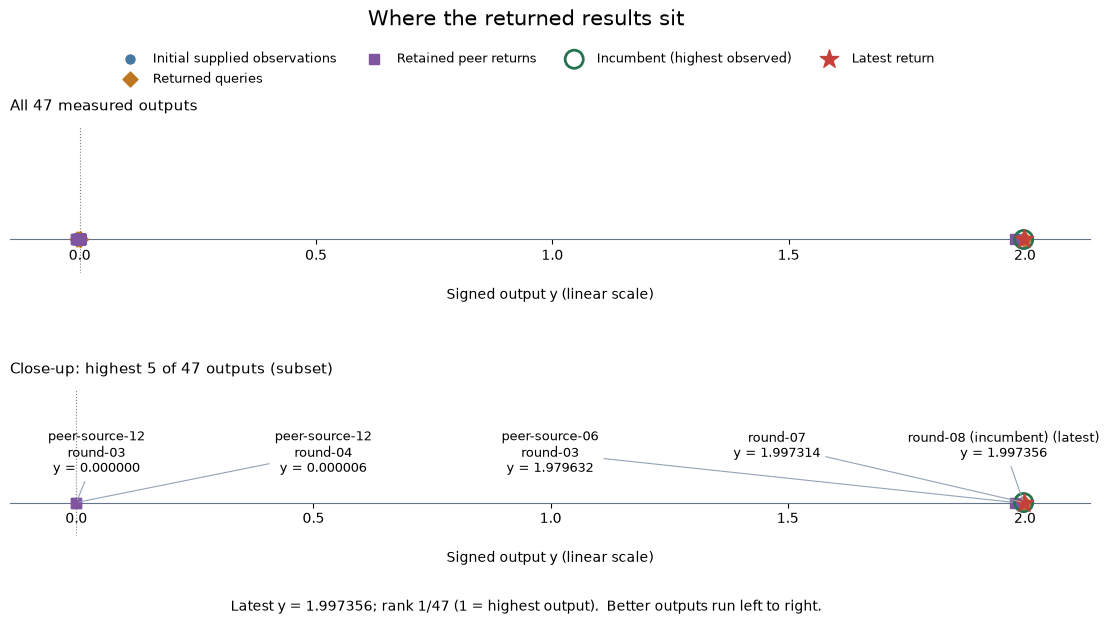

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

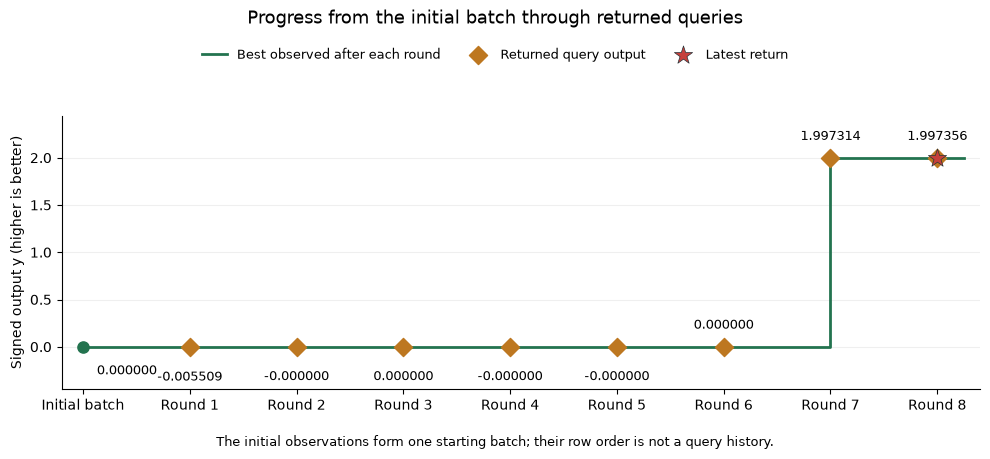

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,7.710875e-16,NaN
Round 1,-5.509346e-03,7.710875e-16,-5.509346e-03
Round 2,-4.057745e-109,7.710875e-16,-7.710875e-16
Round 3,1.972812e-200,7.710875e-16,-7.710875e-16
Round 4,-9.545890e-172,7.710875e-16,-7.710875e-16
Round 5,-1.386359e-94,7.710875e-16,-7.710875e-16
Round 6,2.170913e-14,2.170913e-14,2.093804e-14
Round 7,1.997314e+00,1.997314e+00,1.997314e+00
Round 8,1.997356e+00,1.997356e+00,4.133630e-05


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,y
17,1,round-08,0.628208,0.629204,1.997356e+00
16,2,round-07,0.627916,0.628953,1.997314e+00
33,3,peer-source-06-round-03,0.630000,0.630000,1.979632e+00
38,4,peer-source-12-round-04,0.697000,0.682000,5.656529e-06
37,5,peer-source-12-round-03,0.715000,0.709000,3.843061e-10


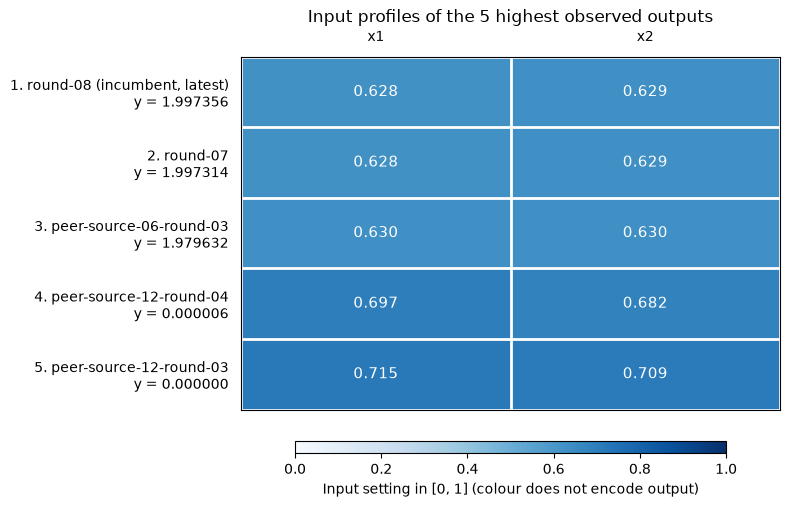

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-23",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 1,
  "intake_date": "2026-11-23",
  "official_rows": 18,
  "peer_rows": 29,
  "new_peer_rows": 3,
  "latest_output": 1.9973556997182018,
  "latest_official_rank": 1,
  "latest_cohort_rank": 1,
  "official_best": 1.9973556997182018,
  "peer_best": 1.979632031622452,
  "best_peer_point": [
    0.63,
    0.63
  ],
  "official_snapshot_sha256": "0afe07ce2fcee5d94b6cb700348f11b9551645fa74dae03472c72617a7336d7b",
  "pooled_snapshot_sha256": "193ebffba964edee3f5571402f6f57b8d8232e161ce363ffffb83f7e46d37b15"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

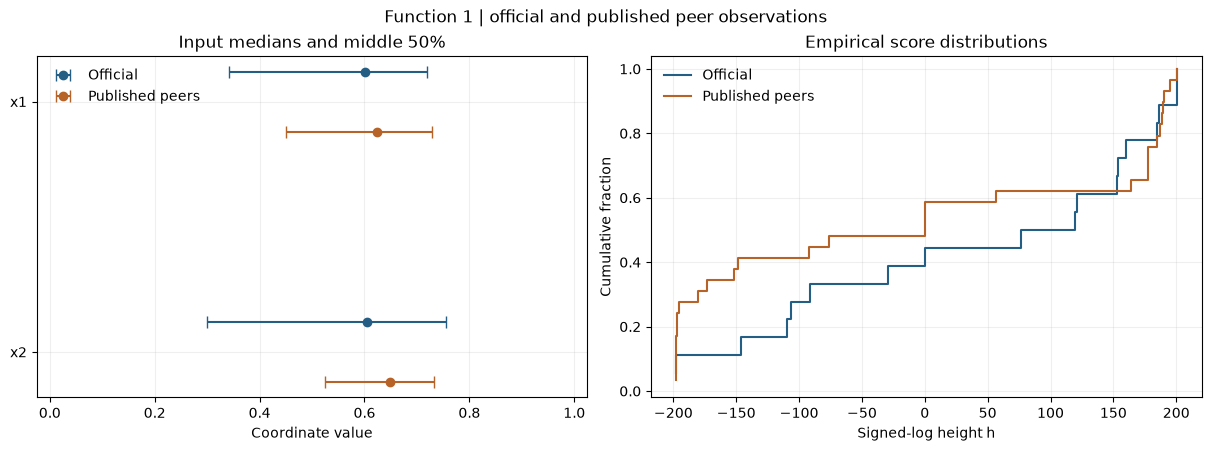

,scope,rows,rows_on_portal_boundary,score_median
0,Official,18,0,98.040548
1,Published peers,29,1,0.000000


portal_input_groups                 46.000000
repeated_input_groups                1.000000
peer_rows_matching_official          1.000000
median_peer_to_official_distance     0.055364
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### What the diagnostics show

The official median signed-log height is 98.04, compared with 0.00 for published peers. The median peer input is 0.0554 units from its nearest official input in the unit box. This is a comparison of observations collected at different points. It helps explain why score preparation and cross-source validation both matter.
